[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch20_Lab10_LSTM.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 20: LSTM and GRU** (Part IV: Meaning and Memory). Also used in Chapter 21.

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=20](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=20)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab 10 — Long Short-Term Memory (LSTM): Next-Number Prediction

**Goal:** understand *why* the LSTM was invented, what each gate does, and how the **cell state** fixes the SimpleRNN's memory problem. Then build, train and test a Keras `LSTM` that predicts the **next number** in a series — the same task as Lab 08 — and finish with a second example covering **many-to-one, many-to-many, one-to-many and encoder–decoder** models using `return_sequences=True`.

| Part | What you do |
|---|---|
| 1 | See the LSTM picture (one cell, and unrolled) |
| 2 | Theory: the 6 equations, what each gate does, why gradients survive, pros and cons |
| 3 | Build the dataset (arithmetic series, same as Lab 08) |
| 4 | Build + train the Keras LSTM; count parameters |
| 5 | Verify the equations by hand against the trained weights; watch the gates |
| 6 | Predict on your own series, and multi-step forecast |
| 7 | LSTM vs SimpleRNN on a long-memory task |
| 8 | Trials to try |
| **B** | **Second example: sequence architectures with `return_sequences=True`** |

> ### ✅ Checked edition (November 2026)
> This notebook was re-run top to bottom and checked for *The Why Book of Deep Learning, Part 1*. What changed from the original:
>
> * **Honest test set.** The original drew 3000 random series from only 1000 distinct ones, so 534 of its 600 test series were also in training. Now each distinct series is used once and split 700 / 100 / 200 into train / validation / test, and the notebook prints the overlap (0).
> * **Validation is no longer the test set:** training watches the validation split; the test split is touched once. (150 epochs instead of 60, because there are fewer, distinct training series.)
> * **§7 now matches its printout.** The text said the SimpleRNN "stays on the baseline"; the original's own run had it at 0.038 against a baseline of 0.171 (4.5× lower), with the LSTM at 0.0012 (about 140× lower). The printout now states each ratio, the text explains why the SimpleRNN gets at best part of the way, and `set_random_seed` makes the comparison repeatable (the SimpleRNN result depends strongly on its starting weights).
> * Part B: after training, `stk.summary()` reports "Total params: 9,845", which includes Adam's state; a line now says the model has 3,281 weights.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, FancyArrowPatch
import tensorflow as tf
from tensorflow.keras import Sequential, Input, Model
from tensorflow.keras.layers import LSTM, SimpleRNN, Dense, RepeatVector

tf.get_logger().setLevel("ERROR")      # hide retracing notices
tf.keras.utils.set_random_seed(42)    # Python, NumPy and TensorFlow in one call: the same run every time
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Picture of an LSTM

**Left:** one LSTM cell. Two lines run through it:
- the **cell state** $c$ (top, thick) — the long-term memory "conveyor belt". It is only touched by a multiply ($\times$, forget) and an add ($+$, write).
- the **hidden state** $h$ (bottom) — the short-term output, like the SimpleRNN's $h$.

Three **gates** (σ, values 0–1) decide what to *forget*, what to *write*, and what to *show*.

**Right:** the same cell **unrolled** over 5 time steps. *Same weights at every step.* Both $c$ and $h$ are passed to the next step.

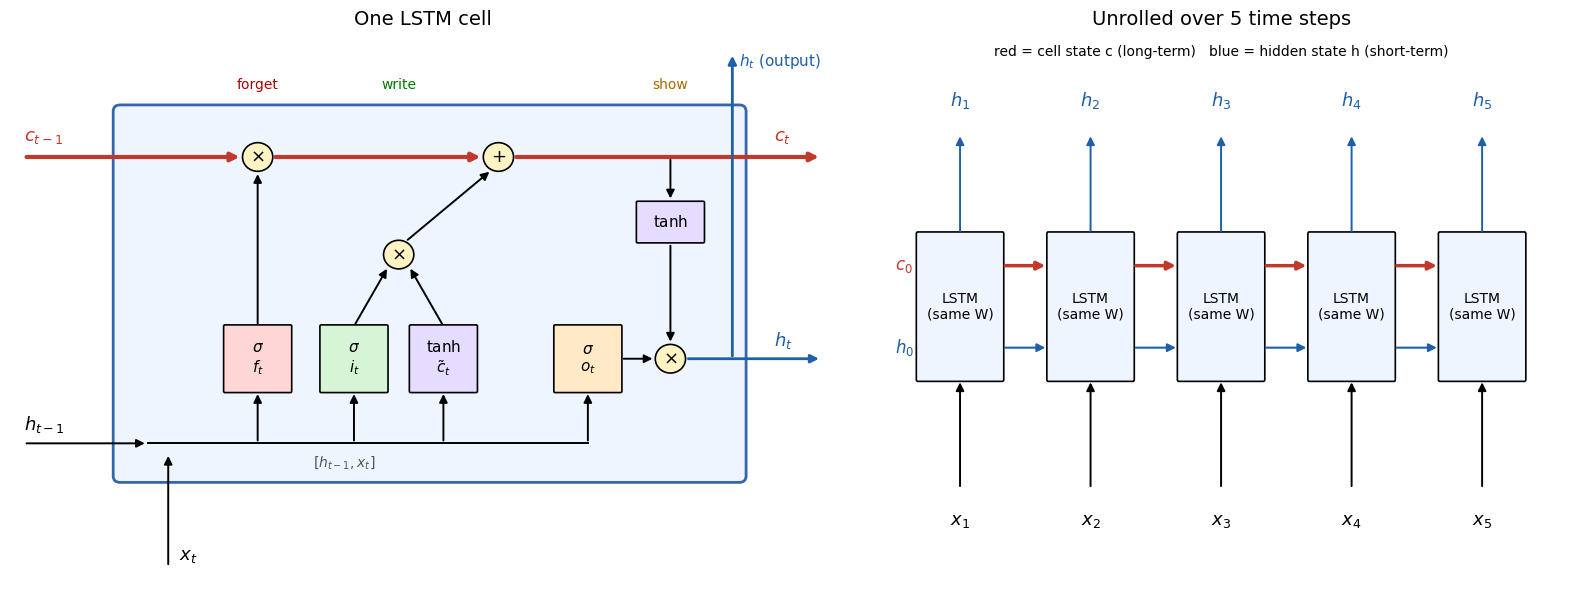

In [2]:
def box(ax, x, y, w, h, text, fc, fs=11):
    ax.add_patch(FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle="round,pad=0.02", fc=fc, ec="k", lw=1.2))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs)
def op(ax, x, y, s, fc="#fff3c4"):
    ax.add_patch(Circle((x, y), 0.22, fc=fc, ec="k", lw=1.2)); ax.text(x, y, s, ha="center", va="center", fontsize=13)
def arr(ax, p, q, lw=1.4, c="k", style="-|>"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=12, lw=lw, color=c))

fig, axs = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.15, 1]})

# ---- one cell
ax = axs[0]; ax.set_xlim(-1, 11); ax.set_ylim(-1.2, 7.2); ax.axis("off")
ax.add_patch(FancyBboxPatch((0.6, 0.4), 9, 5.6, boxstyle="round,pad=0.1", fc="#eef5ff", ec="#3366aa", lw=2))
# cell-state line
arr(ax, (-0.8, 5.3), (2.38, 5.3), lw=3, c="#c0392b"); ax.text(-0.8, 5.55, r"$c_{t-1}$", fontsize=13, color="#c0392b")
op(ax, 2.6, 5.3, r"$\times$")
arr(ax, (2.82, 5.3), (5.88, 5.3), lw=3, c="#c0392b")
op(ax, 6.1, 5.3, "+")
arr(ax, (6.32, 5.3), (10.8, 5.3), lw=3, c="#c0392b"); ax.text(10.1, 5.55, r"$c_t$", fontsize=13, color="#c0392b")
# input line
arr(ax, (-0.8, 0.9), (1.0, 0.9)); ax.text(-0.8, 1.1, r"$h_{t-1}$", fontsize=13)
arr(ax, (1.3, -1.0), (1.3, 0.75)); ax.text(1.45, -0.9, r"$x_t$", fontsize=13)
ax.plot([1.0, 7.4], [0.9, 0.9], "k", lw=1.4); ax.text(3.4, 0.55, r"$[h_{t-1}, x_t]$", fontsize=10, color="#555")
# gates
for x, lab, fc in [(2.6, r"$\sigma$" "\n" r"$f_t$", "#ffd6d6"), (4.0, r"$\sigma$" "\n" r"$i_t$", "#d6f5d6"),
                   (5.3, r"$\tanh$" "\n" r"$\tilde c_t$", "#e5dcff"), (7.4, r"$\sigma$" "\n" r"$o_t$", "#ffe9c7")]:
    arr(ax, (x, 0.9), (x, 1.7)); box(ax, x, 2.2, 0.95, 1.0, lab, fc, fs=11)
arr(ax, (2.6, 2.7), (2.6, 5.08))                      # f -> x
op(ax, 4.65, 3.8, r"$\times$")
arr(ax, (4.0, 2.7), (4.5, 3.62)); arr(ax, (5.3, 2.7), (4.8, 3.62))
arr(ax, (4.75, 4.0), (6.0, 5.1))                      # i*c~ -> +
box(ax, 8.6, 4.3, 0.95, 0.6, r"$\tanh$", "#e5dcff")
arr(ax, (8.6, 5.3), (8.6, 4.62))
op(ax, 8.6, 2.2, r"$\times$")
arr(ax, (7.88, 2.2), (8.38, 2.2)); arr(ax, (8.6, 3.98), (8.6, 2.42))
arr(ax, (8.82, 2.2), (10.8, 2.2), c="#1f5fa8", lw=2); ax.text(10.1, 2.4, r"$h_t$", fontsize=13, color="#1f5fa8")
arr(ax, (9.5, 2.2), (9.5, 6.9), c="#1f5fa8", lw=2); ax.text(9.6, 6.7, r"$h_t$ (output)", fontsize=11, color="#1f5fa8")
ax.text(2.6, 6.35, "forget", ha="center", fontsize=10, color="#a00"); ax.text(4.65, 6.35, "write", ha="center", fontsize=10, color="#070")
ax.text(8.6, 6.35, "show", ha="center", fontsize=10, color="#a60")
ax.set_title("One LSTM cell", fontsize=14)

# ---- unrolled
ax = axs[1]; ax.set_xlim(-0.5, 10.5); ax.set_ylim(-1, 5); ax.axis("off")
xs = [1, 3, 5, 7, 9]
for t, x in enumerate(xs, 1):
    box(ax, x, 2, 1.3, 1.6, f"LSTM\n(same W)", "#eef5ff", fs=10)
    arr(ax, (x, 0.0), (x, 1.2)); ax.text(x, -0.4, rf"$x_{t}$", ha="center", fontsize=13)
    arr(ax, (x, 2.8), (x, 3.9), c="#1f5fa8"); ax.text(x, 4.2, rf"$h_{t}$", ha="center", fontsize=13, color="#1f5fa8")
for a, b in zip(xs[:-1], xs[1:]):
    arr(ax, (a+0.65, 2.45), (b-0.65, 2.45), lw=2.5, c="#c0392b")
    arr(ax, (a+0.65, 1.55), (b-0.65, 1.55), lw=1.5, c="#1f5fa8")
ax.text(0.0, 2.45, r"$c_0$", color="#c0392b", fontsize=12, va="center"); ax.text(0.0, 1.55, r"$h_0$", color="#1f5fa8", fontsize=12, va="center")
ax.text(5, 4.75, "red = cell state c (long-term)   blue = hidden state h (short-term)", ha="center", fontsize=10)
ax.set_title("Unrolled over 5 time steps", fontsize=14)
plt.tight_layout(); plt.show()

## 2. Theory

### 2.1 Why LSTM? (recap of the SimpleRNN problem)
In Lab 08 the SimpleRNN updated memory with one equation, $h_t=\tanh(W_{xh}x_t+W_{hh}h_{t-1}+b_h)$. During BPTT the gradient from step $T$ back to step $k$ is a **product** of Jacobians:

$$\frac{\partial h_T}{\partial h_k}=\prod_{t=k+1}^{T} \operatorname{diag}\!\big(1-h_t^2\big)\,W_{hh}$$

Multiply many numbers $<1$ → **vanishes**; $>1$ → **explodes**. So a SimpleRNN forgets anything more than ~10–20 steps back.

**LSTM idea (Hochreiter & Schmidhuber, 1997):** keep a separate memory line $c_t$ that is updated by **adding**, not by re-squashing through tanh and $W_{hh}$ every step. Gates (learned switches) control the line.

### 2.2 The six equations to remember
$[h_{t-1},x_t]$ means "join the two vectors". $\sigma$ = sigmoid (0 to 1, a soft switch). $\odot$ = element-wise multiply.

| # | Equation | Name | What it does |
|---|---|---|---|
| 1 | $f_t=\sigma(W_f x_t+U_f h_{t-1}+b_f)$ | **Forget gate** | How much of the old memory $c_{t-1}$ to keep (1 = keep all, 0 = erase) |
| 2 | $i_t=\sigma(W_i x_t+U_i h_{t-1}+b_i)$ | **Input gate** | How much of the new candidate to write |
| 3 | $\tilde c_t=\tanh(W_c x_t+U_c h_{t-1}+b_c)$ | **Candidate** | The new information proposed for memory (−1 to 1) |
| 4 | $c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t$ | **Cell state update** | Forget some old + write some new. **The key line** |
| 5 | $o_t=\sigma(W_o x_t+U_o h_{t-1}+b_o)$ | **Output gate** | How much of the memory to reveal now |
| 6 | $h_t=o_t\odot\tanh(c_t)$ | **Hidden state / output** | What the cell outputs and passes on |

**Memory trick:** *forget, write, update, show.* Gates 1, 2, 5 have the **same form** (σ of a weighted sum); only their weights differ.

### 2.3 Why gradients survive — the cell-state highway
From equation 4, ignoring the small indirect paths through the gates:

$$\frac{\partial c_t}{\partial c_{t-1}}\approx f_t \qquad\Rightarrow\qquad \frac{\partial c_T}{\partial c_k}\approx\prod_{t=k+1}^{T} f_t$$

There is **no $W_{hh}$ and no $\tanh'$** in this product. If the network learns $f_t\approx1$ for something it needs to remember, the gradient passes back almost unchanged over many steps. The network itself chooses what to remember (f ≈ 1) and what to drop (f ≈ 0).

Compare: SimpleRNN multiplies by $\operatorname{diag}(1-h^2)\,W_{hh}$ every step (fixed weights, no choice). LSTM multiplies by $f_t$ (a learned, input-dependent value near 1 when needed).

> Keras initialises the forget-gate bias to **1** (`unit_forget_bias=True`), so $f\approx\sigma(1)=0.73$ at the start — "remember by default".

### 2.4 Shapes and parameter count
With $d$ features per step and $n$ units: each of the **4 blocks** ($f, i, \tilde c, o$) has $W\in\mathbb R^{n\times d}$, $U\in\mathbb R^{n\times n}$, $b\in\mathbb R^{n}$.

$$\text{LSTM params}=4\,n\,(d+n+1)\qquad\text{(SimpleRNN: } n(d+n+1)\text{ — LSTM is 4× bigger)}$$

With a `Dense(1)` head add $(n+1)$. For $n=8$, $d=1$: $4\cdot8\cdot10+9=\mathbf{329}$.

In Keras the four blocks are stored side by side in **one** matrix, in the order **i, f, c, o**:
- `kernel` : $(d,\,4n)$  — all the $W$'s
- `recurrent_kernel` : $(n,\,4n)$ — all the $U$'s
- `bias` : $(4n,)$


Part
Shape
Count
Why
W (input weights)
d × n = 1 × 8
8
Each unit sees the 1 input number
U (recurrent weights)
n × n = 8 × 8
64
Each unit sees all 8 previous h values, its own and the others'
b (bias)
n = 8
8
One per unit
One block

80
n(d + n + 1) = 8 × 10
Four blocks (LSTM layer)

320
4n(d + n + 1)
Dense(1) head
8 weights + 1 bias
9
n + 1
Total

329
matches model.summary()

### 2.5 What `return_sequences` and `return_state` give (LSTM)
| Setting | Output |
|---|---|
| default | $h_T$ only, shape `(batch, n)` |
| `return_sequences=True` | $h_1\dots h_T$, shape `(batch, T, n)` |
| `return_state=True` | extra outputs: $h_T$ and **$c_T$** (the cell state — LSTM only) |

### 2.6 Pros and cons
| Pros | Cons |
|---|---|
| Remembers over 100s of steps (vs ~10 for SimpleRNN) | 4× the parameters and compute of SimpleRNN |
| Much less vanishing gradient (additive cell update) | Still sequential: cannot parallelise over time like a Transformer |
| Gates are interpretable (you can plot what it keeps/forgets) | Slower to train; more hyperparameters |
| Robust default for time series, speech, text (pre-Transformer) | Very long contexts (1000s of steps) still hard |
| Exploding gradients rarer (still use clipping for safety) | Overkill for tiny, short-memory tasks |

### 2.7 SimpleRNN vs LSTM vs GRU
| | SimpleRNN | LSTM | GRU |
|---|---|---|---|
| Memory lines | $h$ | $h$ and $c$ | $h$ |
| Gates | 0 | 3 (forget, input, output) | 2 (update, reset) |
| Params ($n$ units, $d$ in) | $n(d+n+1)$ | $4n(d+n+1)$ | $\approx3n(d+n+1)$ |
| Long memory | poor | good | good |
| Use when | teaching, very short sequences | default choice | want LSTM quality with fewer params |

## 3. Dataset — arithmetic series (the same kind as Lab 08)
Each sample is 5 numbers with a constant step, e.g. `[10, 20, 30, 40, 50]` → target `60`.
We divide by `SCALE` so values sit in the useful range of tanh/sigmoid.

There are exactly $100 \times 10 = 1000$ different series (start 0–99, step 1–10). We use each one **once** and split
them into **train / validation / test** with no series in two places. (Drawing 3000 random series, as the first
version of this lab did, repeats each about three times, so most "test" series had already been seen in training.)

In [3]:
T, SCALE = 5, 200.0

# every distinct series once: start 0..99, step 1..10  ->  1000 series
start, step = np.meshgrid(np.arange(0, 100), np.arange(1, 11), indexing="ij")
seq = start.reshape(-1, 1) + step.reshape(-1, 1) * np.arange(T + 1)      # (1000, T+1)
X_raw, y_raw = seq[:, :T].astype("float32"), seq[:, T].astype("float32")
X = (X_raw / SCALE)[..., None]          # (N, T, 1)   d = 1 feature per step
y = y_raw / SCALE                        # (N,)

idx = np.random.permutation(len(X))      # shuffle the DISTINCT series, then split 700 / 100 / 200
tr_i, va_i, te_i = idx[:700], idx[700:800], idx[800:]
X_tr, y_tr = X[tr_i], y[tr_i]
X_va, y_va = X[va_i], y[va_i]
X_te, y_te = X[te_i], y[te_i]

seen = {tuple(s) for s in seq[tr_i]}
print("X shape:", X.shape, " y shape:", y.shape)
print(f"train {len(tr_i)} | validation {len(va_i)} | test {len(te_i)}   "
      f"test series also in training: {sum(tuple(s) in seen for s in seq[te_i])}")
for i in range(3): print(X_raw[i].astype(int), "->", int(y_raw[i]))

X shape: (1000, 5, 1)  y shape: (1000,)
train 700 | validation 100 | test 200   test series also in training: 0
[0 1 2 3 4] -> 5
[0 2 4 6 8] -> 10
[ 0  3  6  9 12] -> 15


## 4. Build and train the LSTM
`LSTM(8)` → `Dense(1)`. Many-to-one: read 5 numbers, output 1.

In [4]:
UNITS = 8
model = Sequential([
    Input(shape=(T, 1)),
    LSTM(UNITS),                 # return_sequences=False -> only h_T
    Dense(1)                     # linear head: y_hat = W h_T + b
])
model.compile(optimizer=tf.keras.optimizers.Adam(0.01), loss="mse", metrics=["mae"])
model.summary()

d = 1
print(f"\nFormula: 4*n*(d+n+1) + (n+1) = 4*{UNITS}*({d}+{UNITS}+1) + {UNITS+1} = {4*UNITS*(d+UNITS+1) + UNITS+1}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 8)              │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 329 (1.29 KB)

 Trainable params: 329 (1.29 KB)

 Non-trainable params: 0 (0.00 B)


Formula: 4*n*(d+n+1) + (n+1) = 4*8*(1+8+1) + 9 = 329


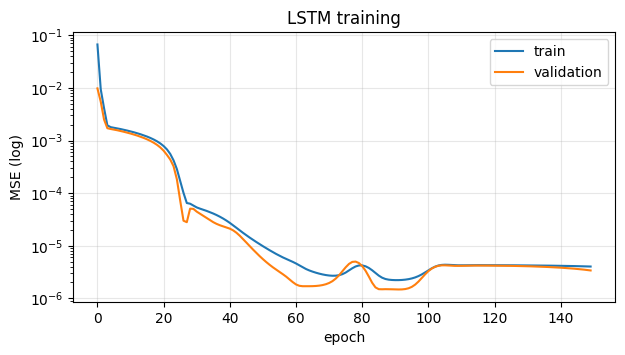

Test MAE = 0.30 (in original units, on 200 series the model never saw)


In [5]:
# validation data = the validation split; the test split is used once, below
hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=150, batch_size=32, verbose=0)

plt.figure(figsize=(7, 3.5))
plt.semilogy(hist.history["loss"], label="train"); plt.semilogy(hist.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE (log)"); plt.title("LSTM training"); plt.legend(); plt.grid(alpha=.3); plt.show()

mae = model.evaluate(X_te, y_te, verbose=0)[1] * SCALE
print(f"Test MAE = {mae:.2f} (in original units, on 200 series the model never saw)")

## 5. Verify the six equations by hand
We pull the trained weights out of Keras, split them into the 4 blocks (order **i, f, c, o**), and run equations 1–6 in NumPy. Then compare with what Keras computes.

In [6]:
kernel, rec_kernel, bias = model.layers[0].get_weights()
Wd, bd = model.layers[1].get_weights()
print("kernel", kernel.shape, " recurrent_kernel", rec_kernel.shape, " bias", bias.shape)

n = UNITS
split4 = lambda M: [M[..., k*n:(k+1)*n] for k in range(4)]     # i, f, c, o
W_i, W_f, W_c, W_o = split4(kernel)
U_i, U_f, U_c, U_o = split4(rec_kernel)
b_i, b_f, b_c, b_o = split4(bias)
sig = lambda z: 1 / (1 + np.exp(-z))

def lstm_by_hand(seq):
    h = np.zeros(n); c = np.zeros(n); log = []
    for x in seq:                                  # x is shape (1,)
        f  = sig(x @ W_f + h @ U_f + b_f)          # 1 forget
        i  = sig(x @ W_i + h @ U_i + b_i)          # 2 input
        ct = np.tanh(x @ W_c + h @ U_c + b_c)      # 3 candidate
        c  = f * c + i * ct                        # 4 cell update
        o  = sig(x @ W_o + h @ U_o + b_o)          # 5 output gate
        h  = o * np.tanh(c)                        # 6 hidden state
        log.append(dict(f=f, i=i, ct=ct, c=c, o=o, h=h))
    return h, c, log

seq = np.array([10, 20, 30, 40, 50], dtype="float32").reshape(T, 1) / SCALE
h_T, c_T, log = lstm_by_hand(seq)
y_hand = (h_T @ Wd + bd)[0] * SCALE

# Keras: get h_T and c_T with return_state
probe_in = Input(shape=(T, 1))
probe_out = LSTM(UNITS, return_sequences=True, return_state=True)(probe_in)
probe = Model(probe_in, probe_out)
probe.layers[1].set_weights(model.layers[0].get_weights())
H_seq, h_k, c_k = [a.numpy() for a in probe(seq[None])]

print("h_T  hand :", np.round(h_T, 4))
print("h_T  keras:", np.round(h_k[0], 4))
print("c_T  hand :", np.round(c_T, 4))
print("c_T  keras:", np.round(c_k[0], 4))
print(f"\nPrediction  hand = {y_hand:.3f}   keras = {model.predict(seq[None], verbose=0)[0,0]*SCALE:.3f}   (true 60)")
print("Max |difference| in h_T:", np.abs(h_T - h_k[0]).max())
print("Last row of return_sequences output equals h_T:", np.allclose(H_seq[0, -1], h_k[0]))

kernel (1, 32)  recurrent_kernel (8, 32)  bias (32,)
h_T  hand : [ 0.0086  0.2358 -0.0815  0.1233 -0.0209 -0.0092  0.1886  0.0525]
h_T  keras: [ 0.0086  0.2358 -0.0815  0.1233 -0.0209 -0.0092  0.1886  0.0525]
c_T  hand : [ 0.0188  0.4748 -0.114   0.2436 -0.0483 -0.0151  0.2984  0.0995]
c_T  keras: [ 0.0188  0.4748 -0.114   0.2436 -0.0483 -0.0151  0.2984  0.0995]



Prediction  hand = 60.172   keras = 60.172   (true 60)
Max |difference| in h_T: 2.0057828092889807e-08
Last row of return_sequences output equals h_T: True


### 5b. Watch the gates
Each panel shows one quantity for all 8 units over the 5 time steps of `[10, 20, 30, 40, 50]`.
- Forget gate values close to 1 = "keep that memory slot".
- The cell state $c$ is **not** limited to [−1, 1] (it is a sum), while $h$ is.
- Colour scales for $\tilde c$, $c$, $h$ are auto-scaled (see colour bars).

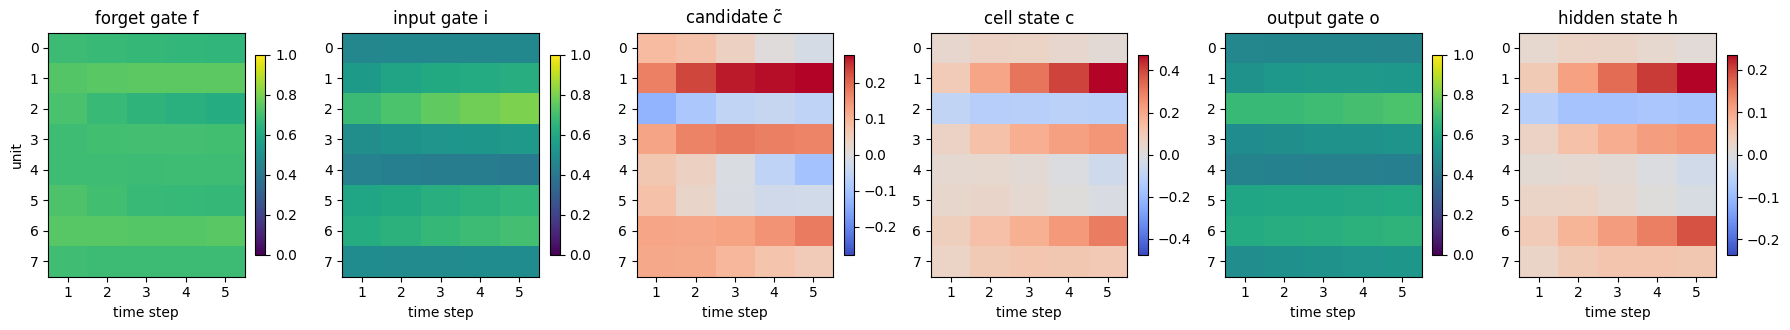

Mean forget gate per step: [0.709 0.701 0.695 0.691 0.688]


In [7]:
names = [("f", "forget gate f"), ("i", "input gate i"), ("ct", r"candidate $\tilde c$"),
         ("c", "cell state c"), ("o", "output gate o"), ("h", "hidden state h")]
fig, axs = plt.subplots(1, 6, figsize=(18, 3.4))
for ax, (k, title) in zip(axs, names):
    A = np.array([s[k] for s in log]).T                    # (units, T)
    if k in ("f", "i", "o"): cmap, vmin, lim = "viridis", 0, 1.0
    else: lim = np.abs(A).max(); cmap, vmin = "coolwarm", -lim      # auto-scaled so small values show
    im = ax.imshow(A, cmap=cmap, vmin=vmin, vmax=lim, aspect="auto")
    ax.set_title(title); ax.set_xlabel("time step"); ax.set_xticks(range(T)); ax.set_xticklabels(range(1, T+1))
    plt.colorbar(im, ax=ax, fraction=.046)
axs[0].set_ylabel("unit")
plt.tight_layout(); plt.show()

print("Mean forget gate per step:", np.round([s["f"].mean() for s in log], 3))

## 6. Predict on your own series
Change `my_series` (any 5 numbers with a constant step). Then a **multi-step forecast**: feed each prediction back in as the newest input.

In [8]:
def predict_next(series):
    x = np.array(series, dtype="float32").reshape(1, T, 1) / SCALE
    return model.predict(x, verbose=0)[0, 0] * SCALE

my_series = [7, 14, 21, 28, 35]
print(my_series, "-> predicted next:", round(predict_next(my_series), 2))

for s in ([3, 6, 9, 12, 15], [50, 55, 60, 65, 70], [90, 98, 106, 114, 122], [150, 160, 170, 180, 190]):
    print(s, "->", round(predict_next(s), 2), "  (true", s[-1] + (s[1]-s[0]), ")")
print("\nNote: the last one is outside the training range — watch the error grow.")

[7, 14, 21, 28, 35] -> predicted next: 41.98
[3, 6, 9, 12, 15] -> 18.1   (true 18 )
[50, 55, 60, 65, 70] -> 75.25   (true 75 )


[90, 98, 106, 114, 122] -> 130.25   (true 130 )


[150, 160, 170, 180, 190] -> 198.24   (true 200 )

Note: the last one is outside the training range — watch the error grow.


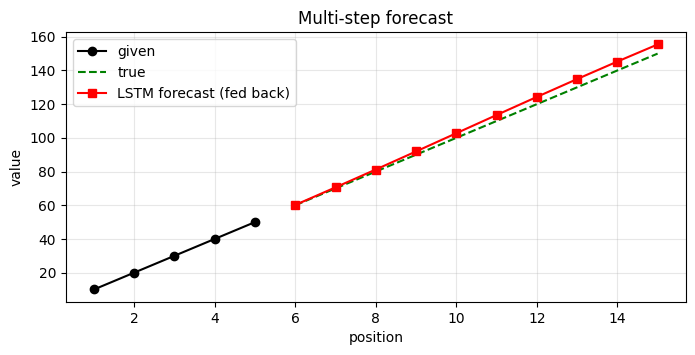

[ 60.2  70.6  81.2  91.9 102.7 113.6 124.3 134.9 145.3 155.4]


In [9]:
def forecast(series, k=10):
    window, out = list(series), []
    for _ in range(k):
        nxt = predict_next(window[-T:]); out.append(nxt); window.append(nxt)
    return out

start = [10, 20, 30, 40, 50]
fc = forecast(start, 10)
true = [start[-1] + 10 * (j + 1) for j in range(10)]
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 6), start, "ko-", label="given")
plt.plot(range(6, 16), true, "g--", label="true")
plt.plot(range(6, 16), fc, "rs-", label="LSTM forecast (fed back)")
plt.xlabel("position"); plt.ylabel("value"); plt.legend(); plt.grid(alpha=.3); plt.title("Multi-step forecast"); plt.show()
print(np.round(fc, 1))

## 7. LSTM vs SimpleRNN on a long-memory task (the "adding problem")
The arithmetic series only needs the last 2 numbers, so both cells do fine. To see what the cell state buys, use the classic test from the original LSTM paper:

> Each step has **2 features**: a random value in [0, 1] and a marker (0 or 1). Exactly **two** steps are marked — one in the first half, one in the second half.
> Target: the **sum of the two marked values**.

With `L = 60` the first marked value can be up to 59 steps back, buried in noise. A model that learns nothing predicts the average sum and gets MSE ≈ 0.17 (the gray line).

Example markers at steps: [19 31]  values: [0.423 0.389]  target: 0.812


SimpleRNN  params =  1153   final val MSE = 0.1793   (baseline = 0.1712: no better than the baseline)


LSTM       params =  4513   final val MSE = 0.0004   (baseline = 0.1712: 383.4x lower)


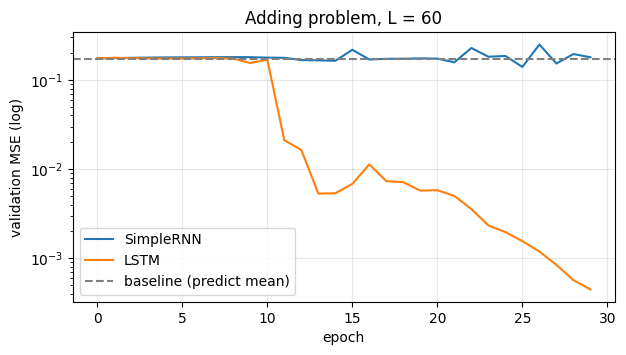

In [10]:
L, NL = 60, 6000
rng = np.random.default_rng(0)
vals = rng.random((NL, L)).astype("float32")
mark = np.zeros((NL, L), "float32")
mark[np.arange(NL), rng.integers(0, L // 2, NL)] = 1          # one marker in first half
mark[np.arange(NL), rng.integers(L // 2, L, NL)] = 1          # one marker in second half
Xa = np.stack([vals, mark], axis=-1)                           # (NL, L, 2)   d = 2
ya = (vals * mark).sum(axis=1)                                 # sum of the 2 marked values
baseline = ya[5000:].var()
print("Example markers at steps:", np.where(mark[0])[0], " values:", np.round(vals[0][mark[0] == 1], 3), " target:", round(ya[0], 3))

results = {}
for name, cell in [("SimpleRNN", SimpleRNN), ("LSTM", LSTM)]:
    tf.keras.utils.set_random_seed(0)     # the same starting weights and shuffles for both cells
    m = Sequential([Input(shape=(L, 2)), cell(32), Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(0.003, clipnorm=1.0), loss="mse")
    h = m.fit(Xa[:5000], ya[:5000], validation_data=(Xa[5000:], ya[5000:]), epochs=30, batch_size=64, verbose=0)
    results[name] = h.history["val_loss"]
    v = h.history['val_loss'][-1]
    print(f"{name:10s} params = {m.count_params():5d}   final val MSE = {v:.4f}   "
          f"(baseline = {baseline:.4f}: " + (f"{baseline / v:,.1f}x lower)" if v < 0.9 * baseline else "no better than the baseline)"))

plt.figure(figsize=(7, 3.5))
for k, v in results.items(): plt.semilogy(v, label=k)
plt.axhline(baseline, color="gray", ls="--", label="baseline (predict mean)")
plt.xlabel("epoch"); plt.ylabel("validation MSE (log)"); plt.title(f"Adding problem, L = {L}"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Read the plot (and the printout, which says how many times below the baseline each cell ends):** the SimpleRNN
gets at best part of the way. Depending on the random start it either hardly leaves the baseline, or uses the
*second* marker (always within the last 30 steps) to get a few times lower; the gradient from the *first* marker,
up to 59 steps back, has mostly vanished before it arrives. The LSTM sits near the baseline for a few epochs, then
"discovers" the markers and drops a hundred times or more: its forget gates learn to hold the first marked value
on the cell-state highway.

With `L = 30` the SimpleRNN does much better (try it). Change the seed in the loop and run again to see how much
the SimpleRNN's result depends on its starting weights, and how little the LSTM's does.

## 8. Trials to try
1. **Units:** `UNITS = 2, 4, 32`. Check the parameter formula against `model.summary()` each time.
2. **Swap the cell:** replace `LSTM` with `SimpleRNN` and `tf.keras.layers.GRU` in Section 4. Compare parameters (89 / 329 / ?) and test MAE.
3. **Forget-gate bias:** `LSTM(UNITS, unit_forget_bias=False)`. Does training start slower?
4. **No scaling:** set `SCALE = 1`. Why does it fail? (Hint: sigmoid and tanh saturate — Section 5b.)
5. **Longer windows:** `T = 10, 20`. Does accuracy change for the arithmetic task? Why not?
6. **Geometric series** (×2 each step) instead of arithmetic. Harder? Try log-scaling the inputs.
7. **Adding problem (Sec 7):** change `L` to 15, 30, 100. Plot final MSE vs L for both cells. Add `GRU` as a third curve.
8. **Force the gate:** after training, set the forget-gate bias `b_f` to −10 by hand (edit `bias[n:2n]`) and predict again. What breaks and why?
9. **Stacked LSTM:** `LSTM(16, return_sequences=True)` → `LSTM(8)` → `Dense(1)`. Why must the first one return sequences? (Answered in Part B.)

---
# Part B — Second example: sequence architectures with `return_sequences=True`

One task family — a **sine wave** — used five ways. The only things that change are the **input/output shapes** and the three Keras switches:
`return_sequences`, `RepeatVector`, and stacking.

| Pattern | Picture | Example here | Key Keras pieces |
|---|---|---|---|
| One-to-one | ○ → ○ | (no recurrence — just `Dense`) | — |
| **Many-to-one** | ○○○○ → ○ | 20 sine values → next value | `LSTM(n)` (`return_sequences=False`) |
| **Many-to-many (synced)** | ○○○○ → ○○○○ | at every step, output the running mean so far | `LSTM(n, return_sequences=True)` + `Dense` |
| **One-to-many** | ○ → ○○○○ | given frequency → generate 20-step sine | `RepeatVector(T)` + `LSTM(..., return_sequences=True)` |
| **Many-to-many (encoder–decoder)** | ○○○○ → ○○○ | 20 past values → next 10 values | `LSTM(n)` → `RepeatVector(10)` → `LSTM(..., return_sequences=True)` |
| **Stacked** | ○○○○ → (○○○○) → ○ | deeper many-to-one | first `LSTM(..., return_sequences=True)` |

**Rule of thumb:** `Dense` after an LSTM with `return_sequences=True` is applied **at every time step with the same weights**, so you get one output per step.

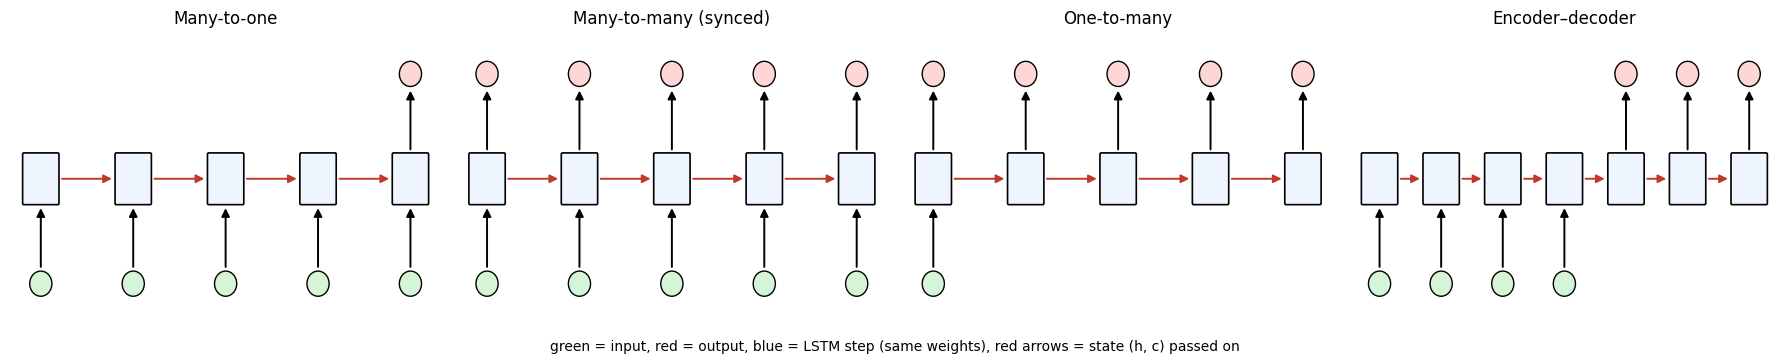

In [11]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.6))
def diagram(ax, n_in, n_out, title, mode):
    ax.set_xlim(-0.5, 6.5); ax.set_ylim(-0.8, 3.6); ax.axis("off"); ax.set_title(title, fontsize=12)
    T_ = max(n_in, n_out) if mode != "encdec" else n_in + n_out
    for t in range(T_):
        x = t * (6 / max(T_ - 1, 1))
        box(ax, x, 1.5, 0.55, 0.7, "", "#eef5ff")
        if t > 0: arr(ax, (x - 6/max(T_-1,1) + 0.3, 1.5), (x - 0.3, 1.5), c="#c0392b")
        has_in  = (mode in ("m2o", "m2m") and t < n_in) or (mode == "o2m" and t == 0) or (mode == "encdec" and t < n_in)
        has_out = (mode == "m2o" and t == T_-1) or mode in ("m2m", "o2m") or (mode == "encdec" and t >= n_in)
        if has_in:  arr(ax, (x, 0.2), (x, 1.12)); ax.add_patch(Circle((x, 0.0), 0.18, fc="#d6f5d6", ec="k"))
        if has_out: arr(ax, (x, 1.88), (x, 2.8)); ax.add_patch(Circle((x, 3.0), 0.18, fc="#ffd6d6", ec="k"))
diagram(axs[0], 5, 1, "Many-to-one", "m2o")
diagram(axs[1], 5, 5, "Many-to-many (synced)", "m2m")
diagram(axs[2], 1, 5, "One-to-many", "o2m")
diagram(axs[3], 4, 3, "Encoder–decoder", "encdec")
fig.text(0.5, 0.01, "green = input, red = output, blue = LSTM step (same weights), red arrows = state (h, c) passed on", ha="center")
plt.tight_layout(); plt.show()

### B.0 Shape probe — what each switch returns
Before training anything, push one dummy batch through each configuration and print the shapes.

In [12]:
Tb, nb = 20, 16
dummy = np.zeros((4, Tb, 1), "float32")            # batch of 4, 20 steps, 1 feature

def shape_of(layers):
    x = Input(shape=(Tb, 1)); y = x
    for l in layers: y = l(y)
    out = Model(x, y)(dummy)
    return [tuple(o.shape) for o in out] if isinstance(out, (list, tuple)) else tuple(out.shape)

print("LSTM(16)                                   ->", shape_of([LSTM(nb)]))
print("LSTM(16, return_sequences=True)            ->", shape_of([LSTM(nb, return_sequences=True)]))
print("LSTM(16, return_state=True)                ->", shape_of([LSTM(nb, return_state=True)]), "  = [h_T, h_T, c_T]")
print("LSTM(16, return_sequences=True) + Dense(1) ->", shape_of([LSTM(nb, return_sequences=True), Dense(1)]))
print("LSTM(16) + RepeatVector(10)                ->", shape_of([LSTM(nb), RepeatVector(10)]))
print("LSTM(16, rs=True) + LSTM(8)                ->", shape_of([LSTM(nb, return_sequences=True), LSTM(8)]))
try:
    shape_of([LSTM(nb), LSTM(8)])
except Exception as e:
    print("LSTM(16) + LSTM(8)                         -> ERROR: second LSTM needs a 3-D sequence input")

LSTM(16)                                   -> (4, 16)
LSTM(16, return_sequences=True)            -> (4, 20, 16)
LSTM(16, return_state=True)                -> [(4, 16), (4, 16), (4, 16)]   = [h_T, h_T, c_T]
LSTM(16, return_sequences=True) + Dense(1) -> (4, 20, 1)


LSTM(16) + RepeatVector(10)                -> (4, 10, 16)
LSTM(16, rs=True) + LSTM(8)                -> (4, 8)
LSTM(16) + LSTM(8)                         -> ERROR: second LSTM needs a 3-D sequence input


### B.1 Shared data — noisy sine waves with random frequency and phase

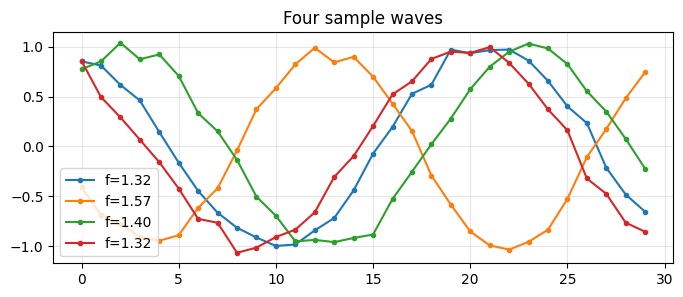

In [13]:
def sine_batch(n, steps, freq=None):
    f = np.random.uniform(0.5, 2.0, n) if freq is None else np.full(n, freq)
    ph = np.random.uniform(0, 2 * np.pi, n)
    t = np.linspace(0, 4 * np.pi, steps)
    return np.sin(f[:, None] * t[None, :] / 2 + ph[:, None]).astype("float32"), f.astype("float32")

S, F = sine_batch(4000, 30)            # 30 points per wave
S_noisy = S + 0.05 * np.random.randn(*S.shape).astype("float32")
tr, te = slice(0, 3200), slice(3200, None)
plt.figure(figsize=(8, 3))
for k in range(4): plt.plot(S_noisy[k], ".-", label=f"f={F[k]:.2f}")
plt.title("Four sample waves"); plt.legend(); plt.grid(alpha=.3); plt.show()

def fit(m, X, Y, epochs=25):
    m.compile(optimizer=tf.keras.optimizers.Adam(0.005), loss="mse")
    h = m.fit(X[tr], Y[tr], validation_data=(X[te], Y[te]), epochs=epochs, batch_size=64, verbose=0)
    print(f"params = {m.count_params():5d}   final val MSE = {h.history['val_loss'][-1]:.5f}")
    return m

### B.2 Many-to-one — read 20 steps, predict step 21
`return_sequences=False`: only $h_{20}$ reaches the head. One answer per sequence. (This is exactly the model of Part A.)

Shapes: `X (N, 20, 1)` → `y (N, 1)`

params =  1169   final val MSE = 0.00145


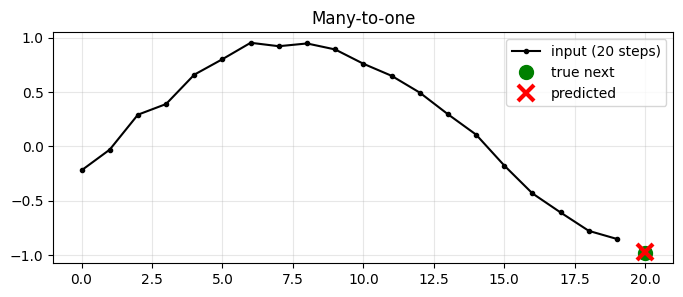

In [14]:
X_m2o = S_noisy[:, :20, None]; Y_m2o = S[:, 20:21]
m2o = fit(Sequential([Input(shape=(20, 1)), LSTM(16), Dense(1)]), X_m2o, Y_m2o)

k = 3201
p = m2o.predict(X_m2o[k:k+1], verbose=0)[0, 0]
plt.figure(figsize=(8, 3)); plt.plot(range(20), X_m2o[k, :, 0], "k.-", label="input (20 steps)")
plt.plot(20, Y_m2o[k, 0], "go", ms=10, label="true next"); plt.plot(20, p, "rx", ms=12, mew=3, label="predicted")
plt.title("Many-to-one"); plt.legend(); plt.grid(alpha=.3); plt.show()

### B.3 Many-to-many (synced) — an output at **every** step
Task: at each step $t$, output the **running mean** of the clean wave so far, $\frac1t\sum_{k\le t}s_k$. The network must keep a running total in memory.

`return_sequences=True` hands $h_1\dots h_{30}$ to `Dense(1)`, which is applied at every step → 30 outputs.

Shapes: `X (N, 30, 1)` → `Y (N, 30, 1)`

params =  1169   final val MSE = 0.00054


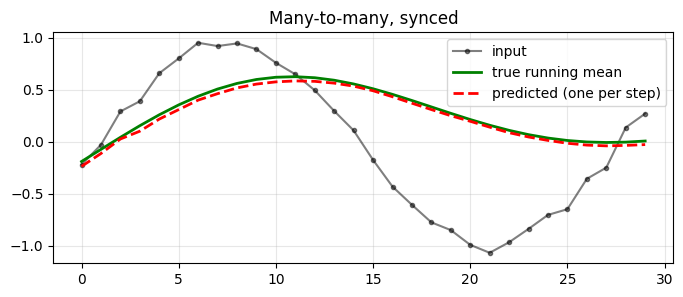

Output shape: (None, 30, 1)


In [15]:
X_m2m = S_noisy[..., None]
Y_m2m = (np.cumsum(S, axis=1) / np.arange(1, 31))[..., None].astype("float32")
m2m = fit(Sequential([Input(shape=(30, 1)), LSTM(16, return_sequences=True), Dense(1)]), X_m2m, Y_m2m)

P = m2m.predict(X_m2m[k:k+1], verbose=0)[0, :, 0]
plt.figure(figsize=(8, 3)); plt.plot(X_m2m[k, :, 0], "k.-", alpha=.5, label="input")
plt.plot(Y_m2m[k, :, 0], "g-", lw=2, label="true running mean"); plt.plot(P, "r--", lw=2, label="predicted (one per step)")
plt.title("Many-to-many, synced"); plt.legend(); plt.grid(alpha=.3); plt.show()
print("Output shape:", m2m.output_shape)

### B.4 One-to-many — one number in, a whole sequence out
Task: input **only the frequency** $f$; output a 20-step sine wave $\sin(f\,t/2)$ (phase fixed at 0).

An LSTM needs a sequence as input, so `RepeatVector(20)` copies the single input 20 times. The LSTM then **generates** with `return_sequences=True`.

Shapes: `X (N, 1)` → `RepeatVector` → `(N, 20, 1)` → LSTM → `(N, 20, 32)` → Dense → `Y (N, 20, 1)`

params =  4385   final val MSE = 0.00010


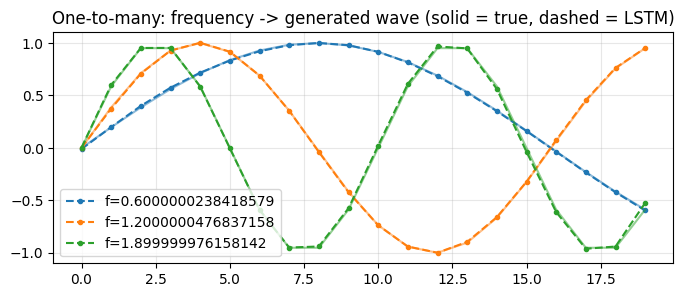

In [16]:
t20 = np.linspace(0, 4 * np.pi, 20)
X_o2m = F[:, None]
Y_o2m = np.sin(F[:, None] * t20[None, :] / 2)[..., None].astype("float32")
o2m = fit(Sequential([Input(shape=(1,)), RepeatVector(20),
                      LSTM(32, return_sequences=True), Dense(1)]), X_o2m, Y_o2m, epochs=40)

plt.figure(figsize=(8, 3))
fqs = np.array([[0.6], [1.2], [1.9]], "float32")
gen = o2m.predict(fqs, verbose=0)[..., 0]
for j, col in enumerate(["C0", "C1", "C2"]):
    plt.plot(np.sin(fqs[j, 0] * t20 / 2), color=col, ls="-", alpha=.5)
    plt.plot(gen[j], color=col, ls="--", marker="o", ms=3, label=f"f={fqs[j,0]}")
plt.title("One-to-many: frequency -> generated wave (solid = true, dashed = LSTM)"); plt.legend(); plt.grid(alpha=.3); plt.show()

### B.5 Many-to-many (encoder–decoder) — input and output lengths differ
Task: read **20** past values, forecast the **next 10** in one shot.

- **Encoder** `LSTM(32)` (`return_sequences=False`) squeezes the 20 inputs into one vector $h_{20}$.
- `RepeatVector(10)` gives the decoder that summary at each of the 10 output steps.
- **Decoder** `LSTM(32, return_sequences=True)` + `Dense(1)` emits 10 values.

Shapes: `X (N, 20, 1)` → `(N, 32)` → `(N, 10, 32)` → `(N, 10, 32)` → `Y (N, 10, 1)`

params = 12705   final val MSE = 0.00366


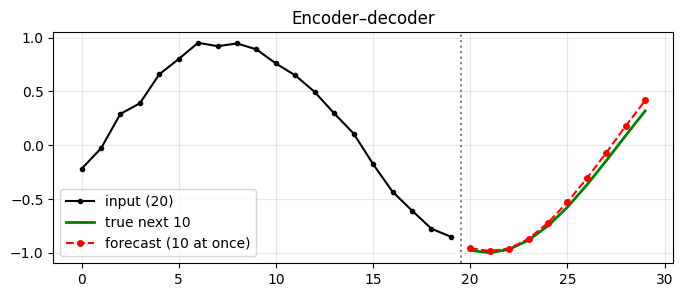

In [17]:
X_ed = S_noisy[:, :20, None]; Y_ed = S[:, 20:30, None]
ed = fit(Sequential([Input(shape=(20, 1)),
                     LSTM(32),                          # encoder
                     RepeatVector(10),                  # bridge
                     LSTM(32, return_sequences=True),   # decoder
                     Dense(1)]), X_ed, Y_ed, epochs=40)

P = ed.predict(X_ed[k:k+1], verbose=0)[0, :, 0]
plt.figure(figsize=(8, 3)); plt.plot(range(20), X_ed[k, :, 0], "k.-", label="input (20)")
plt.plot(range(20, 30), Y_ed[k, :, 0], "g-", lw=2, label="true next 10"); plt.plot(range(20, 30), P, "r--o", ms=4, label="forecast (10 at once)")
plt.axvline(19.5, color="gray", ls=":"); plt.title("Encoder–decoder"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Compare with Section 6:** there we forecast by feeding predictions back one at a time (errors pile up). The encoder–decoder outputs all 10 at once.

### B.6 Stacked LSTM — why the lower layer needs `return_sequences=True`
A second LSTM must read a **sequence**, so every LSTM except the last must return sequences. The last one can be `False` (many-to-one) or `True` (many-to-many).

Same many-to-one task as B.2, now with 2 layers.

In [18]:
stk = fit(Sequential([Input(shape=(20, 1)),
                      LSTM(16, return_sequences=True),   # passes h_1..h_20 up
                      LSTM(16),                          # reads that sequence, returns h_20
                      Dense(1)]), X_m2o, Y_m2o)
stk.summary()
print("(After training, 'Total params' also counts the optimiser's memory: Adam keeps two numbers per weight,")
print(f" so {stk.count_params():,} weights + {2 * stk.count_params():,} optimiser numbers + 2 counters. The model has {stk.count_params():,}.)")

params =  3281   final val MSE = 0.00147


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_17 (LSTM)                  │ (None, 20, 16)         │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_18 (LSTM)                  │ (None, 16)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,845 (38.46 KB)

 Trainable params: 3,281 (12.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,564 (25.64 KB)

(After training, 'Total params' also counts the optimiser's memory: Adam keeps two numbers per weight,
 so 3,281 weights + 6,562 optimiser numbers + 2 counters. The model has 3,281.)


### B.7 Summary table

In [19]:
rows = [("Many-to-one",            m2o, "(N,20,1)", "(N,1)"),
        ("Many-to-many (synced)",  m2m, "(N,30,1)", "(N,30,1)"),
        ("One-to-many",            o2m, "(N,1)",    "(N,20,1)"),
        ("Encoder-decoder",        ed,  "(N,20,1)", "(N,10,1)"),
        ("Stacked many-to-one",    stk, "(N,20,1)", "(N,1)")]
print(f"{'Pattern':24s} {'Input':10s} {'Output':10s} {'Params':>7s}  return_sequences used")
for name, m, i, o in rows:
    rs = [l.return_sequences for l in m.layers if isinstance(l, LSTM)]
    print(f"{name:24s} {i:10s} {o:10s} {m.count_params():7d}  {rs}")

Pattern                  Input      Output      Params  return_sequences used
Many-to-one              (N,20,1)   (N,1)         1169  [False]
Many-to-many (synced)    (N,30,1)   (N,30,1)      1169  [True]
One-to-many              (N,1)      (N,20,1)      4385  [True]
Encoder-decoder          (N,20,1)   (N,10,1)     12705  [False, True]
Stacked many-to-one      (N,20,1)   (N,1)         3281  [True, False]


### B.8 Trials for Part B
1. In B.3, set `return_sequences=False`. What error do you get, and why? Change the target shape to make it train.
2. In B.3, change the task to **running max**. Easier or harder than running mean?
3. In B.4, add the phase as a second input (`Input(shape=(2,))`). Can it generate any shifted sine?
4. In B.5, forecast 20 steps instead of 10. Where does the error grow?
5. Replace every `LSTM` in Part B with `SimpleRNN`. Which pattern suffers most?
6. In B.6, stack 3 layers. Which `return_sequences` flags must be `True`?
7. Use `return_state=True` on the encoder in B.5 and pass `initial_state=[h, c]` to the decoder (functional API). This is the classic seq2seq used in early machine translation.